In [ ]:
!pip -q install huggingface_hub pandas pillow

from huggingface_hub import snapshot_download
from pathlib import Path
import os

# Set ECUSTFD_DIR to your dataset location if it is not ./ecustfd.
# In Google Colab, the default is /content/ecustfd (the notebook working directory).
DATA_DIR = Path(os.environ.get("ECUSTFD_DIR", "ecustfd")).expanduser().resolve()
IMAGE_DIR = DATA_DIR / "images"
required_files = ["annotations.csv", "portions.csv", "food_types.csv"]

if not all((DATA_DIR / name).is_file() for name in required_files) or not IMAGE_DIR.is_dir():
    try:
        snapshot_download(
            repo_id="ai5labsOfficial/ecustfd",
            repo_type="dataset",
            local_dir=str(DATA_DIR)
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not download ECUST-FD. Place the dataset in {DATA_DIR} "
            "or set the ECUSTFD_DIR environment variable to its location."
        ) from exc

missing = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing or not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset is incomplete at {DATA_DIR}. Missing: {missing}; "
        f"images directory exists: {IMAGE_DIR.is_dir()}"
    )

print("Dataset directory:", DATA_DIR)
print("Image directory:", IMAGE_DIR)
print("Image files:", len(list(IMAGE_DIR.glob('*'))))


In [2]:
import pandas as pd
import os

for filename in [
    "annotations.csv",
    "portions.csv",
    "food_types.csv"
]:
    path = os.path.join(DATA_DIR, filename)

    if os.path.isfile(path):
        df = pd.read_csv(path)
        print("\n文件：", filename)
        print("形状：", df.shape)
        print("列名：", df.columns.tolist())
        print(df.head(3))
    else:
        print("没有找到：", filename)


文件： annotations.csv
形状： (6062, 7)
列名： ['file', 'object_id', 'name', 'xmin', 'ymin', 'xmax', 'ymax']
               file object_id   name  xmin  ymin  xmax  ymax
0  apple001S(1).JPG  apple001  apple   326   229   540   401
1  apple001S(1).JPG  apple001   coin   196   344   255   395
2  apple001S(2).JPG  apple001  apple   427   214   649   392

文件： portions.csv
形状： (174, 7)
列名： ['sheet', 'id', 'type', 'volume_mm3', 'weight_g', 'kcal_per_100g', 'calories']
   sheet        id   type  volume_mm3  weight_g  kcal_per_100g  calories
0  apple  apple001  apple         310     244.5             52     127.1
1  apple  apple002  apple         290     232.5             52     120.9
2  apple  apple003  apple         280     219.0             52     113.9

文件： food_types.csv
形状： (19, 4)
列名： ['type', 'kcal_per_100g', 'reference', 'estimated']
     type  kcal_per_100g               reference  estimated
0   apple             52  Apples, raw, with skin      False
1  banana             89            Banan

In [3]:
import os

print("数据目录存在吗？", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    for root, dirs, files in os.walk(DATA_DIR):
        print("\n文件夹：", root)
        print("文件数量：", len(files))
        print("文件示例：", files[:10])


数据目录存在吗？ True

文件夹： /content/ecustfd
文件数量： 5
文件示例： ['.gitattributes', 'annotations.csv', 'food_types.csv', 'portions.csv', 'README.md']

文件夹： /content/ecustfd\.cache
文件数量： 0
文件示例： []

文件夹： /content/ecustfd\.cache\huggingface
文件数量： 2
文件示例： ['.gitignore', 'CACHEDIR.TAG']

文件夹： /content/ecustfd\.cache\huggingface\download
文件数量： 5
文件示例： ['.gitattributes.metadata', 'annotations.csv.metadata', 'food_types.csv.metadata', 'portions.csv.metadata', 'README.md.metadata']

文件夹： /content/ecustfd\.cache\huggingface\download\images
文件数量： 2978
文件示例： ['apple001S(1).JPG.metadata', 'apple001S(2).JPG.metadata', 'apple001T(1).JPG.metadata', 'apple001T(2).JPG.metadata', 'apple002S(1).JPG.metadata', 'apple002S(2).JPG.metadata', 'apple002S(3).JPG.metadata', 'apple002S(4).JPG.metadata', 'apple002S(5).JPG.metadata', 'apple002S(6).JPG.metadata']

文件夹： /content/ecustfd\.cache\huggingface\trees
文件数量： 1
文件示例： ['2000fa65170163e91e7043afbc25b708eaff2236.json']

文件夹： /content/ecustfd\images
文件数量： 2978
文件示例： ['apple001

In [4]:
import pandas as pd
import os

for filename in [
    "annotations.csv",
    "portions.csv",
    "food_types.csv"
]:
    path = os.path.join(DATA_DIR, filename)

    if os.path.isfile(path):
        df = pd.read_csv(path)

        print("\n" + "=" * 40)
        print("文件名：", filename)
        print("行数和列数：", df.shape)
        print("所有列名：", df.columns.tolist())
        display(df.head(5))
    else:
        print("没有找到文件：", filename)


文件名： annotations.csv
行数和列数： (6062, 7)
所有列名： ['file', 'object_id', 'name', 'xmin', 'ymin', 'xmax', 'ymax']


,file,object_id,name,xmin,ymin,xmax,ymax
0,apple001S(1).JPG,apple001,apple,326,229,540,401
1,apple001S(1).JPG,apple001,coin,196,344,255,395
2,apple001S(2).JPG,apple001,apple,427,214,649,392
3,apple001S(2).JPG,apple001,coin,178,346,239,404
4,apple001T(1).JPG,apple001,apple,361,184,585,399



文件名： portions.csv
行数和列数： (174, 7)
所有列名： ['sheet', 'id', 'type', 'volume_mm3', 'weight_g', 'kcal_per_100g', 'calories']


,sheet,id,type,volume_mm3,weight_g,kcal_per_100g,calories
0,apple,apple001,apple,310,244.5,52,127.1
1,apple,apple002,apple,290,232.5,52,120.9
2,apple,apple003,apple,280,219.0,52,113.9
3,apple,apple004,apple,300,234.0,52,121.7
4,apple,apple005,apple,280,212.5,52,110.5



文件名： food_types.csv
行数和列数： (19, 4)
所有列名： ['type', 'kcal_per_100g', 'reference', 'estimated']


,type,kcal_per_100g,reference,estimated
0,apple,52,"Apples, raw, with skin",False
1,banana,89,"Bananas, raw",False
2,bread,238,"Bread, white wheat",False
3,bun,238,"Bread, white wheat (analog)",True
4,doughnut,412,"Doughnuts, french crullers, glazed",False


In [5]:
import pandas as pd
import os

annotations = pd.read_csv(
    os.path.join(DATA_DIR, "annotations.csv")
)
portions = pd.read_csv(
    os.path.join(DATA_DIR, "portions.csv")
)

# 先查看 coin 标注数量
print("annotations 总行数：", len(annotations))
print("coin 标注数量：", (annotations["name"] == "coin").sum())

# 只保留食物标注，排除 coin
food_annotations = annotations[
    annotations["name"] != "coin"
].copy()

# 将食物对象标注与卡路里表连接
merged = food_annotations.merge(
    portions,
    left_on="object_id",
    right_on="id",
    how="left",
    indicator=True
)

print("\n食物标注行数：", len(food_annotations))
print("成功匹配行数：", (merged["_merge"] == "both").sum())
print("未匹配行数：", (merged["_merge"] == "left_only").sum())

print("\n匹配后的示例：")
display(
    merged[
        ["file", "object_id", "name", "weight_g", "calories", "_merge"]
    ].head(10)
)


annotations 总行数： 6062
coin 标注数量： 2976

食物标注行数： 3086
成功匹配行数： 3302
未匹配行数： 0

匹配后的示例：


,file,object_id,name,weight_g,calories,_merge
0,apple001S(1).JPG,apple001,apple,244.5,127.1,both
1,apple001S(2).JPG,apple001,apple,244.5,127.1,both
2,apple001T(1).JPG,apple001,apple,244.5,127.1,both
3,apple001T(2).JPG,apple001,apple,244.5,127.1,both
4,apple002S(1).JPG,apple002,apple,232.5,120.9,both
5,apple002S(2).JPG,apple002,apple,232.5,120.9,both
6,apple002S(3).JPG,apple002,apple,232.5,120.9,both
7,apple002S(4).JPG,apple002,apple,232.5,120.9,both
8,apple002S(5).JPG,apple002,apple,232.5,120.9,both
9,apple002S(6).JPG,apple002,apple,232.5,120.9,both


In [6]:
import pandas as pd
import os

annotations = pd.read_csv(os.path.join(DATA_DIR, "annotations.csv"))
portions = pd.read_csv(os.path.join(DATA_DIR, "portions.csv"))

# 只保留食物标注，不包括 coin
food_annotations = annotations[
    annotations["name"] != "coin"
].copy()

# 检查 portions.csv 中重复的 id
duplicate_ids = portions[
    portions["id"].duplicated(keep=False)
].sort_values("id")

print("portions 总行数：", len(portions))
print("不同 id 数量：", portions["id"].nunique())
print("重复 id 涉及的行数：", len(duplicate_ids))

print("\n重复 ID 示例：")
display(duplicate_ids.head(20))

# 检查是否有同一个 id 对应不同热量
calorie_counts = portions.groupby("id")["calories"].nunique()
conflicting_ids = calorie_counts[calorie_counts > 1]

print("\n对应多个不同热量值的 ID 数量：", len(conflicting_ids))
print(conflicting_ids.head(20))


portions 总行数： 174
不同 id 数量： 160
重复 id 涉及的行数： 28

重复 ID 示例：


,sheet,id,type,volume_mm3,weight_g,kcal_per_100g,calories
93,mix,mix001,apple,280,219.0,52,113.9
94,mix,mix001,orange,280,197.9,47,93.0
95,mix,mix002,apple,300,238.0,52,123.8
96,mix,mix002,banana,170,155.1,89,138.0
97,mix,mix003,apple,290,236.0,52,122.7
98,mix,mix003,qiwi,120,127.5,61,77.8
99,mix,mix004,apple,350,252.5,52,131.3
100,mix,mix004,qiwi,190,169.0,61,103.1
101,mix,mix005,mango,185,192.3,60,115.4
102,mix,mix005,qiwi,160,152.2,61,92.8



对应多个不同热量值的 ID 数量： 14
id
mix001    2
mix002    2
mix003    2
mix004    2
mix005    2
mix006    2
mix007    2
mix008    2
mix009    2
mix010    2
mix011    2
mix012    2
mix013    2
mix014    2
Name: calories, dtype: int64


In [7]:
import pandas as pd
import os

annotations = pd.read_csv(os.path.join(DATA_DIR, "annotations.csv"))
portions = pd.read_csv(os.path.join(DATA_DIR, "portions.csv"))

# 去掉硬币，只保留食物
food_annotations = annotations[
    annotations["name"].str.lower() != "coin"
].copy()

# 统一食物名称的大小写，去除多余空格
food_annotations["name_key"] = (
    food_annotations["name"].str.strip().str.lower()
)
portions["type_key"] = (
    portions["type"].str.strip().str.lower()
)

# 同时匹配食物 ID 和食物类型
merged = food_annotations.merge(
    portions,
    left_on=["object_id", "name_key"],
    right_on=["id", "type_key"],
    how="left",
    indicator=True,
    validate="many_to_one"
)

print("食物标注行数：", len(food_annotations))
print("匹配后行数：", len(merged))
print("成功匹配：", (merged["_merge"] == "both").sum())
print("未匹配：", (merged["_merge"] == "left_only").sum())

print("\n匹配结果示例：")
display(
    merged[
        ["file", "object_id", "name", "weight_g", "calories", "_merge"]
    ].head(15)
)


食物标注行数： 3086
匹配后行数： 3086
成功匹配： 3085
未匹配： 1

匹配结果示例：


,file,object_id,name,weight_g,calories,_merge
0,apple001S(1).JPG,apple001,apple,244.5,127.1,both
1,apple001S(2).JPG,apple001,apple,244.5,127.1,both
2,apple001T(1).JPG,apple001,apple,244.5,127.1,both
3,apple001T(2).JPG,apple001,apple,244.5,127.1,both
4,apple002S(1).JPG,apple002,apple,232.5,120.9,both
5,apple002S(2).JPG,apple002,apple,232.5,120.9,both
6,apple002S(3).JPG,apple002,apple,232.5,120.9,both
7,apple002S(4).JPG,apple002,apple,232.5,120.9,both
8,apple002S(5).JPG,apple002,apple,232.5,120.9,both
9,apple002S(6).JPG,apple002,apple,232.5,120.9,both


In [8]:
# 找出没有匹配到热量记录的行
unmatched = merged[merged["_merge"] == "left_only"]

print("未匹配数量：", len(unmatched))

display(
    unmatched[
        ["file", "object_id", "name"]
    ]
)

未匹配数量： 1


,file,object_id,name
1754,mix012T(4).JPG,mix012,mango


In [9]:
for _, row in unmatched.iterrows():
    print("\n图片：", row["file"])
    print("食物 ID：", row["object_id"])
    print("食物名称：", row["name"])

    print("\n热量表中相同 ID 的记录：")
    display(
        portions[
            portions["id"].astype(str).str.strip()
            == str(row["object_id"]).strip()
        ][["id", "type", "weight_g", "calories"]]
    )


图片： mix012T(4).JPG
食物 ID： mix012
食物名称： mango

热量表中相同 ID 的记录：


,id,type,weight_g,calories
115,mix012,lemon,92.3,26.8
116,mix012,orange,222.0,104.3


In [10]:
# 查看 mix012 的所有食物标注
display(
    food_annotations[
        food_annotations["object_id"] == "mix012"
    ][["file", "object_id", "name"]]
    .sort_values(["file", "name"])
)

# 查看 portions.csv 中 mix012 的所有记录
display(
    portions[
        portions["id"] == "mix012"
    ][["id", "type", "weight_g", "kcal_per_100g", "calories"]]
)

,file,object_id,name
3394,mix012S(1).JPG,mix012,lemon
3395,mix012S(1).JPG,mix012,orange
3398,mix012S(2).JPG,mix012,lemon
3397,mix012S(2).JPG,mix012,orange
3401,mix012S(3).JPG,mix012,lemon
3400,mix012S(3).JPG,mix012,orange
3404,mix012S(4).JPG,mix012,lemon
3403,mix012S(4).JPG,mix012,orange
3406,mix012T(1).JPG,mix012,lemon
3407,mix012T(1).JPG,mix012,orange


,id,type,weight_g,kcal_per_100g,calories
115,mix012,lemon,92.3,29,26.8
116,mix012,orange,222.0,47,104.3


In [11]:
 # 1. 只保留匹配成功的食物标注
matched = merged[merged["_merge"] == "both"].copy()

# 2. 按图片文件名，把同一张图片中所有食物的热量相加
image_labels = (
    matched.groupby("file", as_index=False)
    .agg(
        total_calories=("calories", "sum"),
        object_ids=("object_id", lambda x: ",".join(sorted(set(x))))
    )
)

# 3. 排除存在未匹配食物标注的图片
bad_files = set(unmatched["file"])

image_labels = image_labels[
    ~image_labels["file"].isin(bad_files)
].copy()

print("可用于训练的图片数量：", len(image_labels))
print("被排除的异常图片数量：", len(bad_files))

print("\n标签示例：")
display(image_labels.head(10))

print("\n总热量统计：")
display(image_labels["total_calories"].describe())

可用于训练的图片数量： 2977
被排除的异常图片数量： 1

标签示例：


,file,total_calories,object_ids
0,apple001S(1).JPG,127.1,apple001
1,apple001S(2).JPG,127.1,apple001
2,apple001T(1).JPG,127.1,apple001
3,apple001T(2).JPG,127.1,apple001
4,apple002S(1).JPG,120.9,apple002
5,apple002S(2).JPG,120.9,apple002
6,apple002S(3).JPG,120.9,apple002
7,apple002S(4).JPG,120.9,apple002
8,apple002S(5).JPG,120.9,apple002
9,apple002S(6).JPG,120.9,apple002



总热量统计：


count    2977.000000
mean      116.880417
std        71.095683
min        25.300000
25%        51.700000
50%       114.300000
75%       155.700000
max       491.400000
Name: total_calories, dtype: float64

In [12]:
import os
import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms

IMAGE_DIR = str(DATA_DIR / "images")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class FoodCalorieDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        image_path = os.path.join(self.image_dir, row["file"])
        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        calories = torch.tensor([float(row["total_calories"])], dtype=torch.float32)
        return image, calories


In [13]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.regressor = nn.Linear(128, 1)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        return self.regressor(x)

In [14]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_samples = 0

    for images, calories in train_loader:
        images = images.to(device)
        calories = calories.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, calories)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


def evaluate(model, val_loader, device):
    model.eval()

    total_squared_error = 0.0
    total_absolute_error = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, calories in val_loader:
            images = images.to(device)
            calories = calories.to(device)

            predictions = model(images)

            total_squared_error += (
                (predictions - calories) ** 2
            ).sum().item()

            total_absolute_error += (
                (predictions - calories).abs()
            ).sum().item()

            total_samples += images.size(0)

    mse = total_squared_error / total_samples
    mae = total_absolute_error / total_samples
    rmse = mse ** 0.5

    return {"MAE": mae, "RMSE": rmse, "MSE": mse}

In [15]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

image_df = image_labels.reset_index(drop=True).copy()

image_df["id_list"] = image_df["object_ids"].fillna("").apply(
    lambda s: [x.strip() for x in s.split(",") if x.strip()]
)

parent = list(range(len(image_df)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[ra] = rb

first_image_for_id = {}
for i, ids in enumerate(image_df["id_list"]):
    for food_id in ids:
        if food_id in first_image_for_id:
            union(i, first_image_for_id[food_id])
        else:
            first_image_for_id[food_id] = i

image_df["group_id"] = [find(i) for i in range(len(image_df))]

print("图片总数：", len(image_df))
print("独立分组数：", image_df["group_id"].nunique())
print("最大分组图片数：", image_df["group_id"].value_counts().max())
print(image_df["group_id"].value_counts().head(10).tolist())

图片总数： 2977
独立分组数： 160
最大分组图片数： 68
[68, 54, 54, 52, 50, 48, 46, 46, 44, 44]


In [16]:
group_sizes = image_df["group_id"].value_counts()

print("分组大小统计：")
print(group_sizes.describe())

print("\n不同大小分组的数量：")
for threshold in [1, 5, 10, 20, 40, 60]:
    print(f"大小 >= {threshold} 的分组数：", (group_sizes >= threshold).sum())

print("\n最小的 20 个分组：")
print(group_sizes.tail(20).tolist())

分组大小统计：
count    160.000000
mean      18.606250
std       12.250066
min        3.000000
25%        8.000000
50%       16.000000
75%       24.500000
max       68.000000
Name: count, dtype: float64

不同大小分组的数量：
大小 >= 1 的分组数： 160
大小 >= 5 的分组数： 157
大小 >= 10 的分组数： 112
大小 >= 20 的分组数： 58
大小 >= 40 的分组数： 12
大小 >= 60 的分组数： 1

最小的 20 个分组：
[7, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 4, 4, 3]


In [17]:
largest_groups = group_sizes.head(5)

for group_id, size in largest_groups.items():
    print(f"\n组 ID: {group_id}, 图片数量: {size}")
    print(image_df.loc[image_df["group_id"] == group_id, "file"].head(15).tolist())


组 ID: 2855, 图片数量: 68
['tomato003S(1).JPG', 'tomato003S(10).JPG', 'tomato003S(11).JPG', 'tomato003S(12).JPG', 'tomato003S(13).JPG', 'tomato003S(14).JPG', 'tomato003S(15).JPG', 'tomato003S(16).JPG', 'tomato003S(17).JPG', 'tomato003S(18).JPG', 'tomato003S(19).JPG', 'tomato003S(2).JPG', 'tomato003S(20).JPG', 'tomato003S(21).JPG', 'tomato003S(22).JPG']

组 ID: 206, 图片数量: 54
['apple017S(1).JPG', 'apple017S(10).JPG', 'apple017S(11).JPG', 'apple017S(12).JPG', 'apple017S(13).JPG', 'apple017S(14).JPG', 'apple017S(15).JPG', 'apple017S(16).JPG', 'apple017S(17).JPG', 'apple017S(18).JPG', 'apple017S(19).JPG', 'apple017S(2).JPG', 'apple017S(20).JPG', 'apple017S(21).JPG', 'apple017S(22).JPG']

组 ID: 2923, 图片数量: 54
['tomato004S(1).JPG', 'tomato004S(10).JPG', 'tomato004S(11).JPG', 'tomato004S(12).JPG', 'tomato004S(13).JPG', 'tomato004S(14).JPG', 'tomato004S(15).JPG', 'tomato004S(16).JPG', 'tomato004S(17).JPG', 'tomato004S(18).JPG', 'tomato004S(19).JPG', 'tomato004S(2).JPG', 'tomato004S(20).JPG', 'tomato

In [18]:
from sklearn.model_selection import GroupShuffleSplit

split1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trainval_idx, test_idx = next(split1.split(image_df, groups=image_df["group_id"]))
trainval = image_df.iloc[trainval_idx].copy()
test_df = image_df.iloc[test_idx].copy()

split2 = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=42)
train_idx, val_idx = next(split2.split(trainval, groups=trainval["group_id"]))
train_df = trainval.iloc[train_idx].copy()
val_df = trainval.iloc[val_idx].copy()

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])
print("Train/Val 重叠组数：", len(train_groups & val_groups))
print("Train/Test 重叠组数：", len(train_groups & test_groups))
print("Val/Test 重叠组数：", len(val_groups & test_groups))

Train: 1998
Validation: 446
Test: 533
Train/Val 重叠组数： 0
Train/Test 重叠组数： 0
Val/Test 重叠组数： 0


In [19]:
from torch.utils.data import DataLoader

train_dataset = FoodCalorieDataset(train_df, IMAGE_DIR, train_transform)
val_dataset   = FoodCalorieDataset(val_df,   IMAGE_DIR, val_test_transform)
test_dataset  = FoodCalorieDataset(test_df,  IMAGE_DIR, val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, calories = next(iter(train_loader))
print("图片 Tensor 形状：", images.shape)
print("热量标签形状：", calories.shape)
print("像素值范围：", round(images.min().item(), 2), "到", round(images.max().item(), 2))

Train batches: 63
Validation batches: 14
Test batches: 17
图片 Tensor 形状： torch.Size([32, 3, 224, 224])
热量标签形状： torch.Size([32, 1])
像素值范围： -2.12 到 2.64


In [20]:
import torch
import torch.nn as nn
import numpy as np
import random

seed = 42
random.seed(seed); np.random.seed(seed)
torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model_cnn = SimpleCNN().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_cnn.parameters(), lr=1e-3)

EPOCHS = 10
best_val_mae = float("inf")

for epoch in range(EPOCHS):
    train_mse = train_one_epoch(model_cnn, train_loader, criterion, optimizer, device)
    val_metrics = evaluate(model_cnn, val_loader, device)

    print(f"Epoch [{epoch+1}/{EPOCHS}] Train MSE: {train_mse:.2f} | "
          f"Val MAE: {val_metrics['MAE']:.2f} | Val RMSE: {val_metrics['RMSE']:.2f}")

    if val_metrics["MAE"] < best_val_mae:
        best_val_mae = val_metrics["MAE"]
        torch.save(model_cnn.state_dict(), "best_simplecnn.pth")
        print("  Saved best model.")

Device: cpu
Epoch [1/10] Train MSE: 8038.10 | Val MAE: 82.07 | Val RMSE: 97.56
  Saved best model.
Epoch [2/10] Train MSE: 4994.65 | Val MAE: 81.78 | Val RMSE: 97.74
  Saved best model.
Epoch [3/10] Train MSE: 4726.92 | Val MAE: 82.93 | Val RMSE: 100.14
Epoch [4/10] Train MSE: 4763.41 | Val MAE: 81.07 | Val RMSE: 97.09
  Saved best model.
Epoch [5/10] Train MSE: 4667.88 | Val MAE: 80.79 | Val RMSE: 96.44
  Saved best model.
Epoch [6/10] Train MSE: 4615.24 | Val MAE: 80.00 | Val RMSE: 95.60
  Saved best model.
Epoch [7/10] Train MSE: 4607.37 | Val MAE: 80.36 | Val RMSE: 95.73
Epoch [8/10] Train MSE: 4518.70 | Val MAE: 80.80 | Val RMSE: 96.84
Epoch [9/10] Train MSE: 4550.72 | Val MAE: 78.77 | Val RMSE: 92.81
  Saved best model.
Epoch [10/10] Train MSE: 4557.25 | Val MAE: 79.49 | Val RMSE: 95.38


In [21]:
import numpy as np
import torch

train_mean = train_df["total_calories"].mean()
test_actual = test_df["total_calories"].to_numpy()

baseline_mae = np.mean(np.abs(test_actual - train_mean))
baseline_rmse = np.sqrt(np.mean((test_actual - train_mean) ** 2))

print(f"Baseline prediction: {train_mean:.2f} kcal")
print(f"Baseline Test MAE:   {baseline_mae:.2f} kcal")
print(f"Baseline Test RMSE:  {baseline_rmse:.2f} kcal")

model_cnn.load_state_dict(torch.load("best_simplecnn.pth", map_location=device))
test_metrics = evaluate(model_cnn, test_loader, device)

print("\nSimpleCNN (best checkpoint)")
print(f"Test MAE:  {test_metrics['MAE']:.2f} kcal")
print(f"Test RMSE: {test_metrics['RMSE']:.2f} kcal")
print(f"Test MSE:  {test_metrics['MSE']:.2f}")

Baseline prediction: 112.42 kcal
Baseline Test MAE:   51.82 kcal
Baseline Test RMSE:  61.79 kcal

SimpleCNN (best checkpoint)
Test MAE:  51.25 kcal
Test RMSE: 62.40 kcal
Test MSE:  3893.15


In [22]:
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models

class ResNetCalorie(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, 1)
        )

    def forward(self, x):
        return self.backbone(x)


def train_loop(model, loader, criterion, optimizer, device, freeze_backbone_bn=False):
    model.train()
    if freeze_backbone_bn:
        model.backbone.eval()
        model.backbone.fc.train()
    total_loss, n = 0.0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device).float()
        optimizer.zero_grad()
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        n += imgs.size(0)
    return total_loss / n


def val_metrics_fn(model, loader, device):
    model.eval()
    total_se, total_ae, n = 0.0, 0.0, 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device).float()
            pred = model(imgs)
            total_se += ((pred - labels) ** 2).sum().item()
            total_ae += (pred - labels).abs().sum().item()
            n += imgs.size(0)
    mse = total_se / n
    mae = total_ae / n
    return mse, mae, math.sqrt(mse)


def test_model(model, loader, device):
    model.eval()
    preds, gts = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device).float()
            preds.append(model(imgs).cpu())
            gts.append(labels.cpu())
    preds, gts = torch.cat(preds), torch.cat(gts)
    mae = torch.mean(torch.abs(preds - gts)).item()
    rmse = torch.sqrt(torch.mean((preds - gts) ** 2)).item()
    print(f"ResNet Test MAE: {mae:.2f} kcal | Test RMSE: {rmse:.2f} kcal")
    return preds, gts, mae, rmse


seed = 42
random.seed(seed); np.random.seed(seed)
torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model_rn = ResNetCalorie(dropout=0.3).to(device)
criterion = nn.MSELoss()
save_path = "best_resnet18.pth"
best_val_mae = float("inf")

# ---------- Stage 1：冻结主干，只训回归头 ----------
print("==== Stage1: freeze backbone, train head only ====")
for name, param in model_rn.backbone.named_parameters():
    param.requires_grad = ("fc" in name)

opt1 = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_rn.parameters()),
    lr=1e-3, weight_decay=1e-4
)
sch1 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt1, mode="min", factor=0.5, patience=2)

for epoch in range(10):
    train_mse = train_loop(model_rn, train_loader, criterion, opt1, device, freeze_backbone_bn=True)
    val_mse, val_mae, val_rmse = val_metrics_fn(model_rn, val_loader, device)
    sch1.step(val_mse)
    print(f"[RN S1] Epoch {epoch+1:2d} | Train MSE {train_mse:.1f} | Val MAE {val_mae:.2f} | Val RMSE {val_rmse:.2f}")
    if val_mae < best_val_mae:
        best_val_mae = val_mae
        torch.save(model_rn.state_dict(), save_path)
        print("  Saved best ResNet.")

# ---------- Stage 2：解冻 layer4 + fc 微调 ----------
print("\n==== Stage2: unfreeze layer4 + fc ====")
for name, param in model_rn.backbone.named_parameters():
    param.requires_grad = ("layer4" in name) or ("fc" in name)

opt2 = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model_rn.parameters()),
    lr=1e-4, weight_decay=1e-4
)
sch2 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt2, mode="min", factor=0.5, patience=2)

for epoch in range(10):
    train_mse = train_loop(model_rn, train_loader, criterion, opt2, device)
    val_mse, val_mae, val_rmse = val_metrics_fn(model_rn, val_loader, device)
    sch2.step(val_mse)
    print(f"[RN S2] Epoch {epoch+1:2d} | Train MSE {train_mse:.1f} | Val MAE {val_mae:.2f} | Val RMSE {val_rmse:.2f}")
    if val_mae < best_val_mae:
        best_val_mae = val_mae
        torch.save(model_rn.state_dict(), save_path)
        print("  Saved best ResNet.")

# ---------- 测试集最终评估 ----------
model_rn.load_state_dict(torch.load(save_path, map_location=device))
preds, gts, test_mae, test_rmse = test_model(model_rn, test_loader, device)
print(f"\nBest ResNet | Test MAE: {test_mae:.2f} | Test RMSE: {test_rmse:.2f}")


Device: cpu
==== Stage1: freeze backbone, train head only ====
[RN S1] Epoch  1 | Train MSE 14662.7 | Val MAE 115.99 | Val RMSE 147.63
  Saved best ResNet.
[RN S1] Epoch  2 | Train MSE 10595.2 | Val MAE 101.58 | Val RMSE 131.95
  Saved best ResNet.
[RN S1] Epoch  3 | Train MSE 7970.5 | Val MAE 93.43 | Val RMSE 119.91
  Saved best ResNet.
[RN S1] Epoch  4 | Train MSE 6344.9 | Val MAE 88.22 | Val RMSE 111.49
  Saved best ResNet.
[RN S1] Epoch  5 | Train MSE 5440.3 | Val MAE 84.87 | Val RMSE 105.57
  Saved best ResNet.
[RN S1] Epoch  6 | Train MSE 4995.3 | Val MAE 82.79 | Val RMSE 101.86
  Saved best ResNet.
[RN S1] Epoch  7 | Train MSE 4726.9 | Val MAE 81.49 | Val RMSE 99.33
  Saved best ResNet.
[RN S1] Epoch  8 | Train MSE 4610.3 | Val MAE 80.65 | Val RMSE 97.78
  Saved best ResNet.
[RN S1] Epoch  9 | Train MSE 4530.7 | Val MAE 80.03 | Val RMSE 96.75
  Saved best ResNet.
[RN S1] Epoch 10 | Train MSE 4447.0 | Val MAE 79.51 | Val RMSE 95.99
  Saved best ResNet.

==== Stage2: unfreeze laye

Test 标签 std: 61.75 kcal
ResNet R²:     0.739
ResNet MAPE:   20.0%
预测范围:      30.0 ~ 301.1 kcal


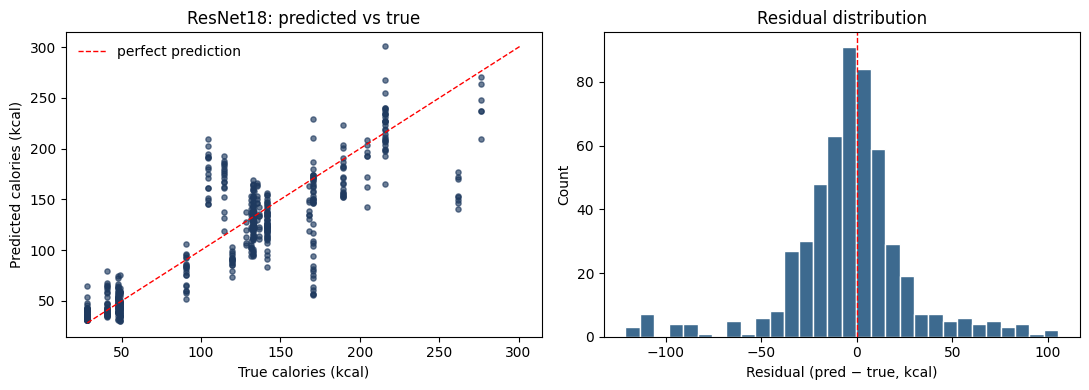

In [23]:
import numpy as np
import matplotlib.pyplot as plt

y = gts.numpy().ravel()
p = preds.numpy().ravel()

ss_res = np.sum((y - p) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r2 = 1 - ss_res / ss_tot
mape = np.mean(np.abs((y - p) / y)) * 100

print(f"Test 标签 std: {y.std():.2f} kcal")
print(f"ResNet R²:     {r2:.3f}")
print(f"ResNet MAPE:   {mape:.1f}%")
print(f"预测范围:      {p.min():.1f} ~ {p.max():.1f} kcal")


fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(y, p, s=14, alpha=0.65, color="#1f3a5f")
lim = [min(y.min(), p.min()), max(y.max(), p.max())]
axes[0].plot(lim, lim, "r--", lw=1, label="perfect prediction")
axes[0].set_xlabel("True calories (kcal)")
axes[0].set_ylabel("Predicted calories (kcal)")
axes[0].set_title("ResNet18: predicted vs true")
axes[0].legend(loc="upper left", frameon=False)

res = p - y
axes[1].hist(res, bins=30, color="#3d6a8f", edgecolor="white")
axes[1].axvline(0, color="r", ls="--", lw=1)
axes[1].set_xlabel("Residual (pred − true, kcal)")
axes[1].set_ylabel("Count")
axes[1].set_title("Residual distribution")

plt.tight_layout()
plt.show()

In [24]:
import numpy as np
import pandas as pd

# 1) 预测值的聚集程度：把预测四舍五入到 5 kcal 桶
print("预测值最集中的 12 个桶：")
print(pd.Series((np.round(p / 5) * 5)).value_counts().head(12))

# 2) 预测是否有落在真实范围之外
print(f"\ntest 真实范围: {y.min():.1f} ~ {y.max():.1f}")
print(f"预测范围:     {p.min():.1f} ~ {p.max():.1f}")
print(f"低于真实下界的预测数: {(p < y.min()).sum()}")
print(f"高于真实上界的预测数: {(p > y.max()).sum()}")

# 3) test 集真实分布
print("\ntest 标签分布：")
print(test_df["total_calories"].describe())

预测值最集中的 12 个桶：
35.0     40
40.0     39
45.0     32
120.0    23
135.0    23
130.0    21
125.0    19
155.0    19
50.0     17
145.0    17
150.0    16
55.0     15
Name: count, dtype: int64

test 真实范围: 28.3 ~ 276.5
预测范围:     30.0 ~ 301.1
低于真实下界的预测数: 0
高于真实上界的预测数: 1

test 标签分布：
count    533.000000
mean     114.447092
std       61.811827
min       28.300000
25%       49.200000
50%      131.300000
75%      141.700000
max      276.500000
Name: total_calories, dtype: float64


In [ ]:
import pandas as pd
import numpy as np

# Category-mean oracle (diagnostic): use the first listed food category for each image.
# For mixed-food images this is an approximation, not a strict full-category oracle.
id2type = portions.set_index("id")["type"].to_dict()

def first_listed_id(object_ids):
    ids = [x.strip() for x in str(object_ids).split(",") if x.strip()]
    return ids[0] if ids else None

test_view = test_df.copy()
test_view["oracle_type"] = (
    test_view["object_ids"].apply(first_listed_id).map(id2type)
)

# Estimate each category mean using training images only (no test-label leakage).
train_types = train_df.copy()
train_types["oracle_type"] = (
    train_types["object_ids"].apply(first_listed_id).map(id2type)
)
type_mean = train_types.groupby("oracle_type")["total_calories"].mean()

test_view["pred_category_mean_oracle"] = test_view["oracle_type"].map(type_mean)
test_view = test_view.dropna(subset=["pred_category_mean_oracle"])

y_oracle = test_view["total_calories"].to_numpy()
p_oracle = test_view["pred_category_mean_oracle"].to_numpy()
mae_oracle = np.mean(np.abs(y_oracle - p_oracle))
rmse_oracle = np.sqrt(np.mean((y_oracle - p_oracle) ** 2))

print(f"Category-mean oracle (first-listed category) | coverage {len(test_view)}/{len(test_df)} images")
print(f"MAE  {mae_oracle:.2f} kcal")
print(f"RMSE {rmse_oracle:.2f} kcal")
print("Note: mixed-food images use only the first listed object ID; interpret this as an approximate category oracle, not a strict upper bound.")
